# **Лабораторна робота №3**
## **Знайомство з нейронними мережами**
***Студент:*** Мельник Владислав

***Група:*** ФБ-61мп

***Датасет для завдання 1:*** TON-Iot Network Dataset

***Датасет для завдання 2:*** Malimg Original

***Датасет для завдання 3:*** Scam and Non-Scam Call Conversation Dataset



# **Мета роботи**
***Мета:*** Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.
# **Підготовка середовища**
Роботу виконано у Google Colab із використанням Python та бібліотеки PyTorch. Для підготовки даних використано NumPy, Pandas і Scikit-learn, для побудови графіків — Matplotlib, а для роботи із зображеннями — Torchvision. Дані TON-IoT і телефонних розмов завантажено у тимчасову папку /content, а Malimg Original отримано за допомогою kagglehub.

Перед проведенням експериментів перевірено доступність файлів і визначено обчислювальний пристрій. У збереженому запуску використовувався CPU (PyTorch 2.14.1+cpu). Це потрібно враховувати під час порівняння часу навчання: наведені значення характеризують конкретний запуск, а не абсолютну швидкодію моделей.


In [ ]:
!pip -q install gensim kagglehub
import os, re, time, random, collections, zipfile, shutil, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from torchvision import datasets, transforms, models
from torchvision.datasets import ImageFolder
from PIL import Image

BASE=Path('/content')
DATA=BASE
MODELS=BASE/'Lab3_Models'
MODELS.mkdir(parents=True,exist_ok=True)
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:',torch.__version__,'Пристрій:',device)
print('Файли у /content:',[p.name for p in DATA.iterdir() if p.is_file()])
required=['train_test_network.csv','English_Scam.txt','English_NonScam.txt']
for name in required:
    print(name, 'ЗНАЙДЕНО' if (DATA/name).is_file() else 'ПОТРІБНО ЗАВАНТАЖИТИ')

PyTorch: 2.14.1+cpu Пристрій: cpu
Файли у /content: ['train_test_network.csv', 'English_Scam.txt', 'English_NonScam.txt']
train_test_network.csv ЗНАЙДЕНО
English_Scam.txt ЗНАЙДЕНО
English_NonScam.txt ЗНАЙДЕНО


# 1. **Класифікація табличних даних за допомогою MLP**
## 1.1. **Завантаження та підготовка TON-IoT Network Dataset**
У першому завданні продовжено роботу з набором TON-IoT Network Dataset, який використано у лабораторній №1 для класифікації мережевого трафіку. Початкова таблиця містить 211 043 записи та 44 стовпці. Стовпці label і type не використовувалися як вхідні ознаки, тому для класифікації залишилися 42 характеристики мережевих з'єднань. Змінна label визначає належність запису до нормального або атакувального трафіку.

Дані було поділено на навчальну, валідаційну й тестову частини. Для порівнянності з попередньою лабораторною залишено окрему тестову вибірку розміром 20%. Пропущені значення оброблялися, числові ознаки масштабовано, а категоріальні кодувалися в числовому вигляді. Параметри цих перетворень визначалися за навчальною вибіркою, після чого застосовувалися до решти даних. Такий підхід зменшує ризик витоку інформації з тестової вибірки.

У результаті сформовано 135 067 навчальних, 33 767 валідаційних і 42 209 тестових записів. За типами стовпців програма визначила 16 числових та 26 категоріальних ознак.

In [ ]:
path=DATA/'train_test_network.csv'
assert path.is_file(), f'Не знайдено {path}'
df=pd.read_csv(path)
assert {'label','type'}.issubset(df.columns)
feature_cols=[c for c in df.columns if c not in ['label','type']]
assert len(feature_cols)==42, f'Очікуємо 42 ознаки, знайдено {len(feature_cols)}'
X_raw=df[feature_cols].replace([np.inf,-np.inf],np.nan).copy()
y=df['label'].astype('int64').to_numpy()
assert set(np.unique(y))=={0,1}
# ТОЙ САМИЙ TEST SPLIT, що й у Lab 1
all_idx=np.arange(len(y))
trainval_idx,test_idx=train_test_split(all_idx,test_size=.2,random_state=SEED)
train_idx,val_idx=train_test_split(trainval_idx,test_size=.2,random_state=SEED,stratify=y[trainval_idx])
cat_cols=X_raw.select_dtypes(include=['object','category','string']).columns.tolist()
num_cols=[c for c in feature_cols if c not in cat_cols]
# На різних копіях датасету можливі змішані типи значень
X_raw[cat_cols]=X_raw[cat_cols].astype('string').fillna('MISSING').astype(str)
for c in num_cols: X_raw[c]=pd.to_numeric(X_raw[c],errors='coerce')
prep=ColumnTransformer([
 ('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num_cols),
 ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('encode',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1))]),cat_cols)
],sparse_threshold=0)
Xtr=prep.fit_transform(X_raw.iloc[train_idx]).astype('float32')
Xva=prep.transform(X_raw.iloc[val_idx]).astype('float32')
Xte=prep.transform(X_raw.iloc[test_idx]).astype('float32')
# Захист від inf / NaN та переповнення float32
Xtr=np.nan_to_num(Xtr,nan=0,posinf=0,neginf=0)
Xva=np.nan_to_num(Xva,nan=0,posinf=0,neginf=0)
Xte=np.nan_to_num(Xte,nan=0,posinf=0,neginf=0)
ytr=y[train_idx];yva=y[val_idx];yte=y[test_idx]
print('Dataset:',df.shape)
print('X:', Xtr.shape)
print('num:', len(num_cols))
print('cat:', len(cat_cols))
print('Train / validation / test:',len(train_idx),len(val_idx),len(test_idx))
print('Розподіл у test:',np.bincount(yte))
print('Ознаки:',feature_cols)

Dataset: (211043, 44)
X: (135067, 42)
num: 16
cat: 26
Train / validation / test: 135067 33767 42209
Розподіл у test: [10021 32188]
Ознаки: ['src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']


## **1.2. Побудова та навчання повнозв'язаної нейронної мережі**
Для розв'язання задачі створено модель MLP із 42 вхідними ознаками, двома прихованими шарами на 64 і 32 нейрони та вихідним шаром на два класи. У прихованих шарах використано функцію активації ReLU, а Dropout із коефіцієнтом 0,2 — для зменшення ризику перенавчання.

Навчання проводилося з оптимізатором Adam і функцією втрат CrossEntropyLoss протягом 12 епох. На кожній епосі обчислювалися середні втрати для навчальної та валідаційної вибірок і валідаційну точність. Це дозволяє простежити, як змінюється якість моделі, а не орієнтуватися лише на кінцеве значення Accuracy.

Epoch 01: train loss=0.2193, val loss=0.1075, val acc=0.975
Epoch 02: train loss=0.0793, val loss=0.0425, val acc=0.990
Epoch 03: train loss=0.0421, val loss=0.0290, val acc=0.993
Epoch 04: train loss=0.0292, val loss=0.0195, val acc=0.995
Epoch 05: train loss=0.0244, val loss=0.0185, val acc=0.996
Epoch 06: train loss=0.0217, val loss=0.0186, val acc=0.996
Epoch 07: train loss=0.0195, val loss=0.0149, val acc=0.996
Epoch 08: train loss=0.0188, val loss=0.0214, val acc=0.995
Epoch 09: train loss=0.0170, val loss=0.0160, val acc=0.997
Epoch 10: train loss=0.0146, val loss=0.0151, val acc=0.997
Epoch 11: train loss=0.0149, val loss=0.0155, val acc=0.997
Epoch 12: train loss=0.0133, val loss=0.0148, val acc=0.997


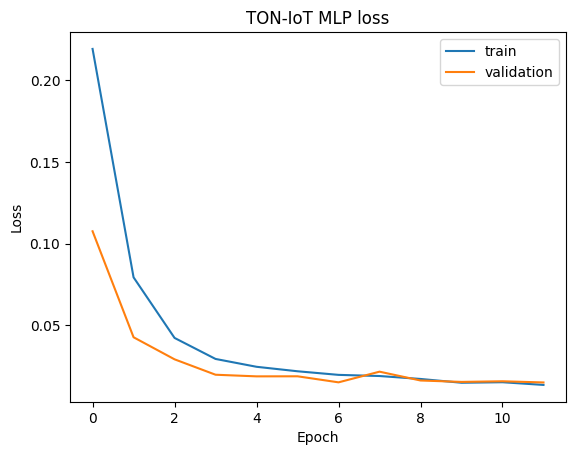

MLP seconds: 42.76


In [ ]:
train_dl=DataLoader(TensorDataset(torch.tensor(Xtr),torch.tensor(ytr,dtype=torch.long)),batch_size=256,shuffle=True)
val_dl=DataLoader(TensorDataset(torch.tensor(Xva),torch.tensor(yva,dtype=torch.long)),batch_size=512)
test_dl=DataLoader(TensorDataset(torch.tensor(Xte),torch.tensor(yte,dtype=torch.long)),batch_size=512)
mlp=nn.Sequential(nn.Linear(Xtr.shape[1],64),nn.ReLU(),nn.Dropout(.2),nn.Linear(64,32),nn.ReLU(),nn.Linear(32,2)).to(device)
opt=torch.optim.Adam(mlp.parameters(),lr=.001)
loss_fn=nn.CrossEntropyLoss()
def run_epoch(model,loader,optimizer=None):
    train=optimizer is not None
    model.train(train)
    total_loss=correct=total=0
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        if train:optimizer.zero_grad()
        with torch.set_grad_enabled(train):
            logits=model(xb); loss=loss_fn(logits,yb)
            if train:loss.backward();optimizer.step()
        total_loss+=loss.item()*len(yb); correct+=(logits.argmax(1)==yb).sum().item();total+=len(yb)
    return total_loss/total,correct/total
hist_mlp={'train_loss':[],'val_loss':[],'train_acc':[],'val_acc':[]}
start=time.perf_counter()
for epoch in range(12):
    tl,ta=run_epoch(mlp,train_dl,opt);vl,va=run_epoch(mlp,val_dl)
    for k,v in zip(hist_mlp,[tl,vl,ta,va]):hist_mlp[k].append(v)
    print(f'Epoch {epoch+1:02d}: train loss={tl:.4f}, val loss={vl:.4f}, val acc={va:.3f}')
mlp_seconds=time.perf_counter()-start
plt.plot(hist_mlp['train_loss'],label='train');plt.plot(hist_mlp['val_loss'],label='validation');plt.legend();plt.xlabel('Epoch');plt.ylabel('Loss');plt.title('TON-IoT MLP loss');plt.show()
print('MLP seconds:',round(mlp_seconds,2))

***Аналіз результатів навчання MLP.*** На початку навчання значення train loss становило 0,2193, а на дванадцятій епосі зменшилося до 0,0133. Валідаційні втрати за цей час загалом знизилися з 0,1075 до 0,0148. Валідаційна точність поступово зростала та наприкінці становила приблизно 99,7%.

На графіку спостерігаються окремі коливання валідаційних втрат, зокрема на восьмій епосі. Проте ці коливання не сформували стійкої тенденції до погіршення результатів. Загалом протягом 12 епох навчальні та валідаційні втрати зменшувалися, тому виражених ознак перенавчання моделі не виявлено. Отримані результати свідчать про здатність MLP ефективно класифікувати мережевий трафік. Водночас порівняння з Random Forest показало, що складніша архітектура не завжди забезпечує кращу якість класифікації та менший час навчання.
## **1.3. Тестування MLP та порівняння з Random Forest**
Щоб оцінити, чи дає нейронна мережа перевагу над класичним машинним навчанням, порівняв її з Random Forest, який раніше застосовувався у лабораторній №1. У межах цього експерименту Random Forest було навчено повторно на підготовленій навчальній вибірці, а обидві моделі оцінено на тих самих тестових записах.

Для порівняння використано Accuracy, Macro F1-score та час навчання. Показник Macro F1 особливо корисний тоді, коли розподіл класів нерівномірний, оскільки надає однакову вагу F1 кожного класу.

In [ ]:
_,mlp_test_acc=run_epoch(mlp,test_dl)
from sklearn.metrics import classification_report
mlp.eval();pred_mlp=[]
with torch.no_grad():
    for xb,_ in test_dl: pred_mlp.extend(mlp(xb.to(device)).argmax(1).cpu().numpy())
print('MLP classification report:\n')
print(classification_report(yte,pred_mlp,zero_division=0))
rf=RandomForestClassifier(n_estimators=100,random_state=SEED,n_jobs=-1)
start=time.perf_counter();rf.fit(Xtr,ytr);rf_seconds=time.perf_counter()-start
rf_pred=rf.predict(Xte)
comparison1=pd.DataFrame([
 {'model':'MLP','test_accuracy':mlp_test_acc,'macro_F1':f1_score(yte,pred_mlp,average='macro',zero_division=0),'seconds':mlp_seconds},
 {'model':'Random Forest (повторно на train)','test_accuracy':accuracy_score(yte,rf_pred),'macro_F1':f1_score(yte,rf_pred,average='macro',zero_division=0),'seconds':rf_seconds}
])
display(comparison1)
print('\nRF classification report:\n')
print(classification_report(yte,rf_pred,zero_division=0))
torch.save({'model_state':mlp.state_dict(),'input_dim':Xtr.shape[1],'seed':SEED,'train_loss':hist_mlp},MODELS/'ton_iot_mlp.pth')
print('MLP checkpoint збережено:',MODELS/'ton_iot_mlp.pth')
print('Примітка: точність з Lab 1 може відрізнятися через покращення процедури encoding та validation.')

MLP classification report:

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209



,model,test_accuracy,macro_F1,seconds
0,MLP,0.996896,0.995709,42.764965
1,Random Forest (повторно на train),0.999953,0.999935,13.716676



RF classification report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     10021
           1       1.00      1.00      1.00     32188

    accuracy                           1.00     42209
   macro avg       1.00      1.00      1.00     42209
weighted avg       1.00      1.00      1.00     42209

MLP checkpoint збережено: /content/Lab3_Models/ton_iot_mlp.pth
Примітка: точність з Lab 1 може відрізнятися через покращення процедури encoding та validation.


***Висновки до завдання 1.*** За результатами тестування MLP забезпечила точність 99,6896%, Macro F1 0,9957, а час її навчання становив 42,76 с. Random Forest отримав вищу точність — 99,9953% — та Macro F1 0,9999, витративши на навчання приблизно 13,72&nbsp;с.

Отже, в експерименті Random Forest виявився не лише точнішим, а й швидшим за MLP. Це не означає, що повнозв'язані нейронні мережі загалом неефективні, проте для цих структурованих даних і вибраних налаштувань класичний ансамблевий алгоритм виявився доцільнішим. Порівняння також показало, чому важливо оцінювати практичні результати, а не вважати складнішу архітектуру автоматично кращою.
# **2. Класифікація зображень за допомогою згорткових нейронних мереж**
## **2.1. Завантаження та аналіз Malimg Original**
Для другого завдання обрано датасет Malimg Original, який містить зображення, сформовані на основі вмісту зразків шкідливого програмного забезпечення. Кожне зображення належить до однієї з 25 родин malware. Набір було завантажено засобами kagglehub; загалом він містить 9 339 зображень.

Спочатку перевірено структуру папок і кількість зразків у кожному класі. Виявилося, що розподіл нерівномірний: наприклад, клас Allaple.A містить 2 949 зображень, тоді як Skintrim.N — лише 80. Через це висока загальна точність ще не гарантує однаково якісного розпізнавання кожної родини. Тому разом з Accuracy у цьому завданні використовується Macro F1-score.

In [ ]:
image_exts={'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
local_folder=Path('/content/malimg_paper_dataset_imgs')
if local_folder.is_dir():
    extract_path=local_folder
    print('Використовуємо локальну папку:',extract_path)
else:
    zip_files=sorted(Path('/content').glob('*.zip'))
    malimg_zip=next((p for p in zip_files if 'malimg' in p.name.lower()),None)
    if malimg_zip is None and len(zip_files)==1: malimg_zip=zip_files[0]
    if malimg_zip is not None:
        extract_path=Path('/content/Malimg_Original')
        extract_path.mkdir(parents=True,exist_ok=True)
        if not any(extract_path.iterdir()):
            with zipfile.ZipFile(malimg_zip,'r') as archive:
                root=extract_path.resolve()
                for member in archive.infolist():
                    target=(extract_path/member.filename).resolve()
                    assert target==root or root in target.parents,'Небезпечний шлях у ZIP'
                archive.extractall(extract_path)
        print('Розпаковано архів:',malimg_zip)
    else:
        import kagglehub
        extract_path=Path(kagglehub.dataset_download('ikrambenabd/malimg-original'))
        print('Malimg завантажено KaggleHub:',extract_path)
candidates=[]
for d in [extract_path,*extract_path.rglob('*')]:
    if not d.is_dir():continue
    child_dirs=[p for p in d.iterdir() if p.is_dir()]
    valid=[p for p in child_dirs if any(f.is_file() and f.suffix.lower() in image_exts for f in p.iterdir())]
    if len(valid)>=2:candidates.append((d,len(valid)))
assert candidates,'Не знайдено папки класів. Перевірте структуру Malimg'
data_root=max(candidates,key=lambda z:z[1])[0]
files_by_class={p.name:sum(1 for f in p.iterdir() if f.is_file() and f.suffix.lower() in image_exts) for p in data_root.iterdir() if p.is_dir()}
print('Папка класів:',data_root)
print('Класи:',len(files_by_class))
print('Зображення:',sum(files_by_class.values()))
print(pd.Series(files_by_class).sort_values(ascending=False).to_string())
assert len(files_by_class)==25, 'Очікується 25 класів. Перевірте архів/папки'

Using Colab cache for faster access to the 'malimg-original' dataset.
Malimg завантажено KaggleHub: /kaggle/input/malimg-original
Папка класів: /kaggle/input/malimg-original/malimg_paper_dataset_imgs
Класи: 25
Зображення: 9339
Allaple.A         2949
Allaple.L         1591
Yuner.A            800
Instantaccess      431
VB.AT              408
Fakerean           381
Lolyda.AA1         213
C2LOP.gen!g        200
Alueron.gen!J      198
Lolyda.AA2         184
Dialplatform.B     177
Dontovo.A          162
Lolyda.AT          159
Rbot!gen           158
C2LOP.P            146
Obfuscator.AD      142
Malex.gen!J        136
Swizzor.gen!I      132
Swizzor.gen!E      128
Lolyda.AA3         123
Adialer.C          122
Agent.FYI          116
Autorun.K          106
Wintrim.BX          97
Skintrim.N          80


## **2.2. Візуалізація прикладів зображень**
Для попереднього ознайомлення з датасетом побудовано сітку з 25 прикладів — по одному зображенню від кожного класу. На них помітні різні текстури, смуги та повторювані візерунки. Ці відмінності можуть містити корисні ознаки для класифікації, хоча самі зображення не є звичайними фотографіями об'єктів.

Візуальний перегляд дав змогу переконатися, що файли читаються коректно, а назви класів відповідають структурі папок.

Всього: 9339
Класи: 25


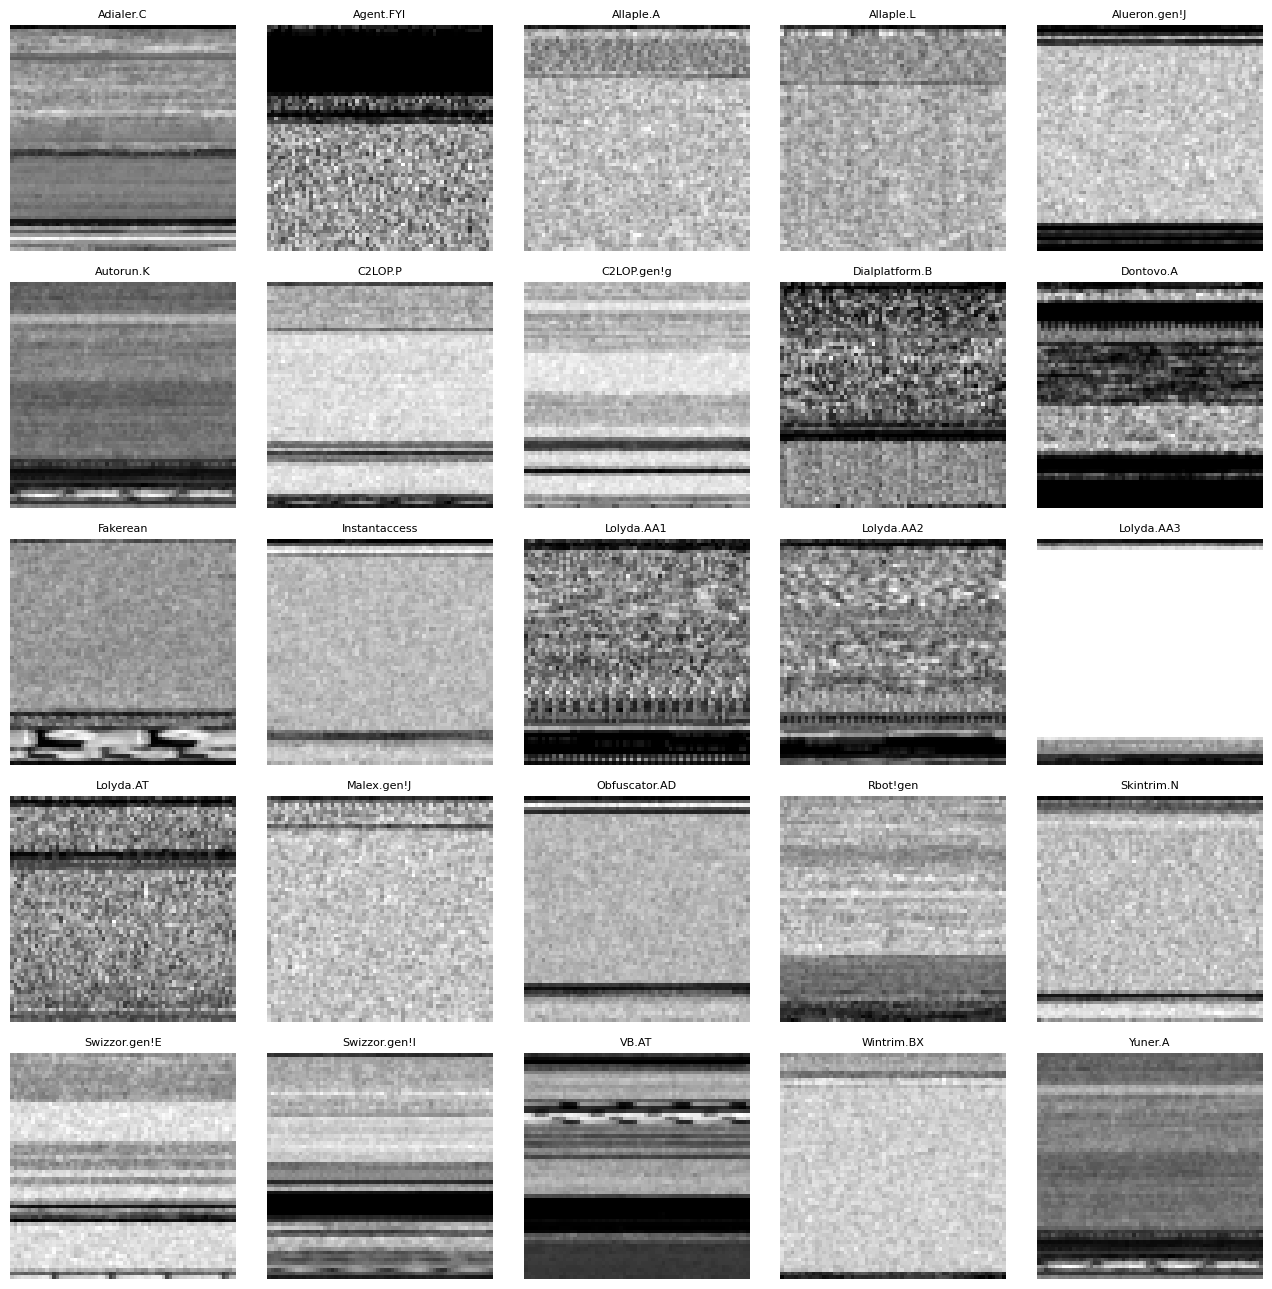

In [ ]:
from torchvision.datasets import ImageFolder
preview=ImageFolder(str(data_root),transform=transforms.Compose([transforms.Grayscale(num_output_channels=1),transforms.Resize((64,64)),transforms.ToTensor()]))
print('Всього:',len(preview))
print('Класи:',len(preview.classes))
fig,axes=plt.subplots(5,5,figsize=(13,13))
for i,ax in enumerate(axes.flat):
    ids=[j for j,(_,label) in enumerate(preview.samples) if label==i]
    if ids:
        sample,_=preview[ids[0]];ax.imshow(sample.squeeze(),cmap='gray')
    ax.set_title(preview.classes[i],fontsize=8);ax.axis('off')
plt.tight_layout();plt.show()

## **2.3. Підготовка зображень і створення Simple CNN**
Перед поданням до нейронної мережі зображення приведено до розміру 96 × 96 пікселів та трьох каналів. Після цього сформовано початковий стратифікований поділ приблизно у співвідношенні 70% / 15% / 15%. Стратифікація потрібна для того, щоб частки класів у вибірках були подібними.

Просту CNN реалізовано з трьома згортковими шарами, активаціями ReLU, шарами пулінгу та повнозв'язаним класифікатором на 25 виходів. Така архітектура є достатньо компактною, щоб використати її як базову модель для подальшого порівняння з ResNet18.

***Уточнення щодо поділу.*** Початковий розподіл нижче було використано тільки для виявлення проблеми дублікатів. Під час подальшого навчання застосовано інший, виправлений поділ, описаний у п. 2.3.1-2.3.3. Це важливо враховувати під час читання збережених результатів клітинок.

In [ ]:
img_tf=transforms.Compose([transforms.Grayscale(num_output_channels=3),transforms.Resize((96,96)),transforms.ToTensor()])
img_ds=ImageFolder(str(data_root),transform=img_tf)
labels=np.array(img_ds.targets); ii=np.arange(len(img_ds))
trv,te=train_test_split(ii,test_size=.15,stratify=labels,random_state=SEED)
tr,va=train_test_split(trv,test_size=.15/.85,stratify=labels[trv],random_state=SEED)
def img_loaders(train_ids, batch=64):
    return (DataLoader(Subset(img_ds,train_ids),batch_size=batch,shuffle=True,num_workers=2),
            DataLoader(Subset(img_ds,va),batch_size=batch,num_workers=2),
            DataLoader(Subset(img_ds,te),batch_size=batch,num_workers=2))
image_tr,image_va,image_te=img_loaders(tr)
print('Train:', len(tr))
print('Val:', len(va))
print('Test:', len(te))
class SimpleCNN(nn.Module):
    def __init__(self,k):
        super().__init__()
        self.features=nn.Sequential(nn.Conv2d(3,16,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(16,32,3,padding=1),nn.ReLU(),nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1),nn.ReLU(),nn.AdaptiveAvgPool2d((1,1)))
        self.fc=nn.Linear(64,k)
    def forward(self,x):return self.fc(self.features(x).flatten(1))
num_classes=len(img_ds.classes)
cnn=SimpleCNN(num_classes).to(device)
print(cnn)

Train: 6537
Val: 1401
Test: 1401
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (fc): Linear(in_features=64, out_features=25, bias=True)
)


### **2.3.1. Перевірка точних дублікатів**
Під час підготовки даних вирішено окремо перевірити, чи немає серед зображень повних копій файлів. Якщо однакове зображення одночасно потрапляє до навчальної та тестової вибірок, оцінка якості може бути завищена. Для перевірки обчислено SHA-256 для кожного файлу та згруповано файли з однаковими хешами. Далі порівнювалися множини хешів у Train, Validation та Test.

In [ ]:
import hashlib
from collections import defaultdict

# Групуємо файли за їхнім вмістом
hash_groups = defaultdict(list)

for idx, (path, label) in enumerate(img_ds.samples):
    with open(path, "rb") as f:
        file_hash = hashlib.file_digest(
            f, "sha256"
        ).hexdigest()

    hash_groups[file_hash].append(idx)

duplicate_groups = {
    h: ids for h, ids in hash_groups.items()
    if len(ids) > 1
}

extra_copies = sum(
    len(ids) - 1
    for ids in duplicate_groups.values()
)

print("Усього зображень:", len(img_ds))
print("Унікальних файлів:", len(hash_groups))
print("Груп дублікатів:", len(duplicate_groups))
print("Зайвих копій:", extra_copies)

# Перевіряємо поточні Train/Val/Test
def get_hashes(indices):
    return {
        h for h, ids in hash_groups.items()
        if any(i in indices for i in ids)
    }

train_h = get_hashes(set(tr))
val_h = get_hashes(set(va))
test_h = get_hashes(set(te))

print("Train ∩ Val:", len(train_h & val_h))
print("Train ∩ Test:", len(train_h & test_h))
print("Val ∩ Test:", len(val_h & test_h))

Усього зображень: 9339
Унікальних файлів: 8444
Груп дублікатів: 260
Зайвих копій: 895
Train ∩ Val: 126
Train ∩ Test: 118
Val ∩ Test: 62


***Результат перевірки.*** Із 9 339 файлів було отримано 8 444 унікальні значення SHA-256. Виявлено 260 груп дублікатів, які містили 895 додаткових копій. У початковому розподілі між Train і Validation збігалися 126 хешів, між Train і Test — 118, а між Validation і Test — 62.

Це підтвердило, що звичайного випадкового поділу в цьому випадку недостатньо. Перш ніж навчати моделі, необхідно було змінити розподіл, не допускаючи потрапляння точних копій до різних вибірок.
### **2.3.2. Повторний поділ з урахуванням дублікатів**
Щоб усунути виявлені перетинання, повторно розподілено дані за групами ідентичних файлів: усі файли з одним SHA-256 залишаються лише в одній із вибірок. Під час поділу враховано мітки класів. При цьому файли не видалялися, отже, загальна кількість зображень залишилася незмінною.

У результаті навчальна вибірка містила 6 540 зображень, валідаційна — 1 403, тестова — 1 396. Кількості трохи відрізняються від початкового поділу, оскільки групи дублікатів мають різний розмір.

In [ ]:
from sklearn.model_selection import train_test_split

# Кожна група складається з однакових файлів
groups = list(hash_groups.values())

group_labels = []

for ids in groups:
    labels_in_group = {
        img_ds.samples[i][1] for i in ids
    }

    if len(labels_in_group) != 1:
        raise ValueError(
            "Знайдено однакові файли з різними класами!"
        )

    group_labels.append(next(iter(labels_in_group)))

group_ids = list(range(len(groups)))

# Розподіл груп на train та тимчасову вибірку
train_g, temp_g = train_test_split(
    group_ids,
    test_size=0.30,
    stratify=group_labels,
    random_state=SEED
)

# Розподіл тимчасової вибірки на val та test
temp_labels = [group_labels[g] for g in temp_g]

val_g, test_g = train_test_split(
    temp_g,
    test_size=0.5,
    stratify=temp_labels,
    random_state=SEED
)

# Відновлюємо індекси зображень
def expand_groups(selected_groups):
    return [
        i
        for group_id in selected_groups
        for i in groups[group_id]
    ]

tr = expand_groups(train_g)
va = expand_groups(val_g)
te = expand_groups(test_g)

# Створюємо нові DataLoader
image_tr, image_va, image_te = img_loaders(tr)

print("Новий розподіл:")
print("Train:", len(tr))
print("Validation:", len(va))
print("Test:", len(te))

Новий розподіл:
Train: 6540
Validation: 1403
Test: 1396


### **2.3.3. Контроль нового розподілу**
Після повторного поділу порівняли хеші SHA-256 між усіма трьома вибірками. Для пар Train-Validation, Train-Test та Validation-Test отримано 0 спільних хешів.

Таким чином, вдалося усунути витік даних саме через точні файлові копії. Водночас SHA-256 не виявляє майже однакових зображень, які можуть бути збережені як різні файли. Тому результати цього контролю не слід трактувати як повну перевірку незалежності всіх зразків.

In [ ]:
train_h = get_hashes(set(tr))
val_h = get_hashes(set(va))
test_h = get_hashes(set(te))

print("Перевірка після нового розподілу:")
print("Train ∩ Val:", len(train_h & val_h))
print("Train ∩ Test:", len(train_h & test_h))
print("Val ∩ Test:", len(val_h & test_h))

assert len(train_h & val_h) == 0
assert len(train_h & test_h) == 0
assert len(val_h & test_h) == 0

print("Успішно: точні дублікати не перетинаються!")

Перевірка після нового розподілу:
Train ∩ Val: 0
Train ∩ Test: 0
Val ∩ Test: 0
Успішно: точні дублікати не перетинаються!


***Підсумок підготовки Malimg.*** Для всіх подальших експериментів використано остаточний поділ: Train — 6 540, Validation — 1 403, Test — 1 396. Контроль SHA-256 показав 0 / 0 / 0 перетинань точних дублікатів. Саме ці вибірки використано для обох моделей на повних даних та для експерименту зі скороченим train.
## **2.4. Навчання простої згорткової нейронної мережі**
На виправленому наборі даних навчено Simple CNN протягом п'яти епох. У моделі використано оптимізатор Adam і функцію втрат CrossEntropyLoss. Після кожної епохи оцінювався train loss, validation loss і validation accuracy. Наприкінці проведено незалежне тестування й розраховано Macro F1-score.

Epoch 1 train/val loss: 0.4802 0.3828 val acc: 0.8753
Epoch 2 train/val loss: 0.4111 0.3644 val acc: 0.881
Epoch 3 train/val loss: 0.376 0.3643 val acc: 0.9066
Epoch 4 train/val loss: 0.3693 0.3217 val acc: 0.9138
Epoch 5 train/val loss: 0.3755 0.3454 val acc: 0.8674
CNN test accuracy: 0.8696275071633238
Macro F1: 0.8207746698623217
Seconds: 414.98231742499956


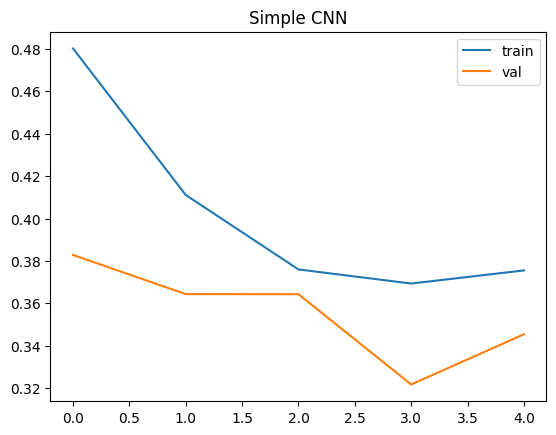

CNN checkpoint збережено


In [ ]:
img_loss=nn.CrossEntropyLoss()
def fit_image(model,trainloader,valloader,epochs=5,lr=.001):
    opt=torch.optim.Adam(filter(lambda p:p.requires_grad,model.parameters()),lr=lr)
    hist={'train':[],'val':[],'val_acc':[]};start=time.perf_counter()
    for epoch in range(epochs):
        for loader,training,key in [(trainloader,True,'train'),(valloader,False,'val')]:
            model.train(training); loss_sum=n=correct=0
            for xb,yb in loader:
                xb,yb=xb.to(device),yb.to(device)
                if training:opt.zero_grad()
                with torch.set_grad_enabled(training):
                    out=model(xb);loss=img_loss(out,yb)
                    if training:loss.backward();opt.step()
                loss_sum+=loss.item()*len(yb);n+=len(yb);correct+=(out.argmax(1)==yb).sum().item()
            hist[key].append(loss_sum/n)
            if not training:hist['val_acc'].append(correct/n)
        print('Epoch',epoch+1,'train/val loss:',round(hist['train'][-1],4),round(hist['val'][-1],4),'val acc:',round(hist['val_acc'][-1],4))
    return hist,time.perf_counter()-start
def image_test(model,loader):
    model.eval();true=[];pred=[]
    with torch.no_grad():
        for xb,yb in loader:
            out=model(xb.to(device)).argmax(1).cpu().numpy()
            pred.extend(out);true.extend(yb.numpy())
    return accuracy_score(true,pred),f1_score(true,pred,average='macro',zero_division=0)
cnn_hist,cnn_sec=fit_image(cnn,image_tr,image_va,epochs=5)
cnn_acc,cnn_f1=image_test(cnn,image_te)
print('CNN test accuracy:', cnn_acc)
print('Macro F1:', cnn_f1)
print('Seconds:', cnn_sec)
plt.plot(cnn_hist['train'],label='train');plt.plot(cnn_hist['val'],label='val');plt.legend();plt.title('Simple CNN');plt.show()
torch.save({'model_state':cnn.state_dict(),'classes':img_ds.classes,'history':cnn_hist},MODELS/'malimg_simple_cnn.pth')
print('CNN checkpoint збережено')

***Аналіз результатів Simple CNN.*** На тестовій вибірці модель досягла 86,96% Accuracy і 0,8208 Macro F1. Навчання тривало приблизно 414,98 с. Втрати загалом зменшувалися до четвертої епохи, на якій отримано найкраще значення validation loss — 0,3217 — та найвищу валідаційну точність 91,38%.

На п'ятій епосі валідаційні втрати збільшилися до 0,3454, а точність знизилася до 86,74%. Це може свідчити про коливання процесу навчання або початкові ознаки перенавчання, але за однією епохою робити однозначні висновки не варто. Різниця між Accuracy та Macro F1 також показує, що результати не однакові для всіх класів, тому лише загальної точності для оцінювання недостатньо.
## **2.5. Донавчання pretrained ResNet18**
Другим підходом використано ResNet18 із попередньо навченими на ImageNet вагами. Початковий класифікатор моделі було замінено на лінійний шар із 25 виходами. Більшу частину параметрів залишили замороженою, тоді як останній згортковий блок layer4 і новий класифікатор брали участь у навчанні. Зображення нормалізувалися відповідно до параметрів ImageNet.

Для порівняння з Simple CNN використано ті самі Train, Validation і Test, створені після перевірки дублікатів, і так само проведено п'ять епох навчання. Отже, склад вибірок залишався контрольованим, а відмінності пов'язані з архітектурою та попередньо навченими вагами.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 138MB/s]


Вихідний шар: Linear(in_features=512, out_features=25, bias=True)
Epoch 1 train/val loss: 0.2519 0.0811 val acc: 0.9708
Epoch 2 train/val loss: 0.0762 0.1511 val acc: 0.9522
Epoch 3 train/val loss: 0.0826 0.0723 val acc: 0.9743
Epoch 4 train/val loss: 0.0866 0.0892 val acc: 0.9715
Epoch 5 train/val loss: 0.0546 0.0915 val acc: 0.9736
ResNet18 test accuracy, macro F1, seconds: 0.9734957020057307 0.919321164645194 1345.5759593030016


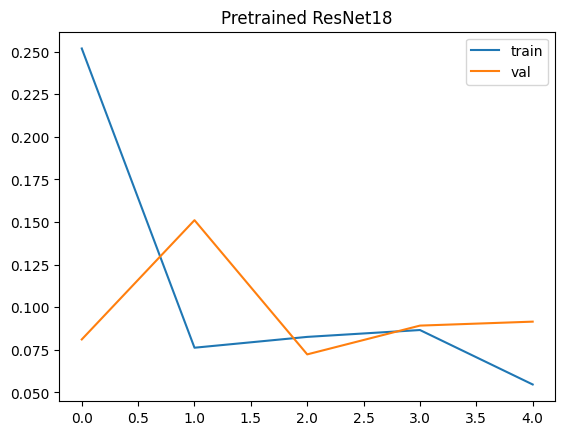

ResNet18 checkpoint збережено


In [ ]:
weights=models.ResNet18_Weights.DEFAULT
resnet=models.resnet18(weights=weights)
for p in resnet.parameters():p.requires_grad=False
for p in resnet.layer4.parameters():p.requires_grad=True
resnet.fc=nn.Linear(resnet.fc.in_features,num_classes)
resnet=resnet.to(device)
print('Вихідний шар:',resnet.fc)
# Для ResNet застосовуємо ImageNet normalization
resnet_tf=transforms.Compose([transforms.Grayscale(num_output_channels=3),transforms.Resize((96,96)),transforms.ToTensor(),transforms.Normalize([.485,.456,.406],[.229,.224,.225])])
resnet_ds=ImageFolder(str(data_root),transform=resnet_tf)
resnet_tr=DataLoader(Subset(resnet_ds,tr),batch_size=64,shuffle=True,num_workers=2)
resnet_va=DataLoader(Subset(resnet_ds,va),batch_size=64,num_workers=2)
resnet_te=DataLoader(Subset(resnet_ds,te),batch_size=64,num_workers=2)
resnet_hist,resnet_sec=fit_image(resnet,resnet_tr,resnet_va,epochs=5,lr=.001)
resnet_acc,resnet_f1=image_test(resnet,resnet_te)
print('ResNet18 test accuracy, macro F1, seconds:',resnet_acc,resnet_f1,resnet_sec)
plt.plot(resnet_hist['train'],label='train');plt.plot(resnet_hist['val'],label='val');plt.legend();plt.title('Pretrained ResNet18');plt.show()
torch.save({'model_state':resnet.state_dict(),'classes':resnet_ds.classes,'history':resnet_hist},MODELS/'malimg_resnet18.pth')
print('ResNet18 checkpoint збережено')

***Аналіз результатів ResNet18.*** Тестова точність становила 97,35%, Macro F1 — 0,9193, час навчання — приблизно 1 345,58 с. Найменший validation loss (0,0723) отримано на третій епосі. На четвертій та п'ятій епохах валідаційні втрати дещо збільшилися, хоча валідаційна точність залишалася високою.

Порівняно з Simple CNN ResNet18 підвищила тестову точність приблизно на 10,39 відсоткового пункта, а Macro F1 — на 0,0985. Водночас вона навчалася приблизно у 3,2 раза довше. Отже, попередньо навчена модель у цьому експерименті забезпечила помітно кращу якість, але потребувала більших обчислювальних витрат. Коливання validation loss не дозволяють виключити початкові ознаки перенавчання, тому для подальших дослідів можна було б застосувати збереження найкращих ваг за валідаційною метрикою.
## **2.6. Порівняння моделей і впливу обсягу навчальних даних**
На завершальному етапі завдання порівнювалися Simple CNN і ResNet18 за точністю, Macro F1, тривалістю навчання та характером графіків валідаційних втрат. Окремо було досліджено, як змінюється якість при скороченні навчальної вибірки.

Для цього сформовано підмножину з приблизно половини навчальних зображень, відбираючи цілі групи ідентичних файлів. Для кожної архітектури створено нову модель і навчено її протягом п'яти епох. При цьому Validation і Test залишилися незмінними, тому результати можна порівнювати на однакових контрольних даних. Відбір половини груп не гарантує точно половини зображень, оскільки розміри груп відрізняються.

Порівняння Simple CNN та ResNet18


,model,test_accuracy,macro_F1,seconds
0,Simple CNN,0.869628,0.820775,414.982317
1,ResNet18 pretrained,0.973496,0.919321,1345.575959


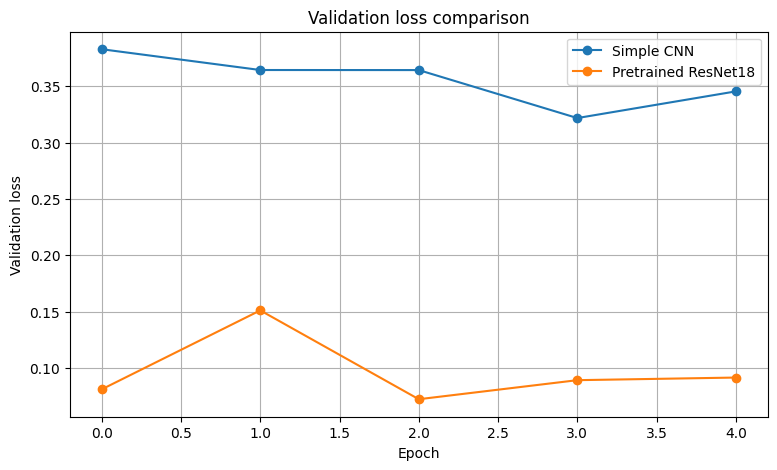


Розміри навчальних вибірок:
Повна train: 6540
Скорочена train: 3268
Validation: 1403
Test: 1396
Перевірка успішна: точні дублікати не перетинаються

Навчання Simple CNN на 50% груп
Epoch 1 train/val loss: 2.6632 2.4169 val acc: 0.3158
Epoch 2 train/val loss: 2.2951 2.0736 val acc: 0.3507
Epoch 3 train/val loss: 1.9085 1.6861 val acc: 0.4163
Epoch 4 train/val loss: 1.5694 1.423 val acc: 0.4726
Epoch 5 train/val loss: 1.3622 1.248 val acc: 0.5795
CNN 50% accuracy: 0.582378223495702
CNN 50% Macro F1: 0.31188575524919954

Навчання ResNet18 на 50% груп
Epoch 1 train/val loss: 0.3656 0.1738 val acc: 0.9401
Epoch 2 train/val loss: 0.0993 0.1014 val acc: 0.9636
Epoch 3 train/val loss: 0.0714 0.1267 val acc: 0.9651
Epoch 4 train/val loss: 0.0721 0.1045 val acc: 0.9694
Epoch 5 train/val loss: 0.0705 0.2933 val acc: 0.9209
ResNet18 50% accuracy: 0.9276504297994269
ResNet18 50% Macro F1: 0.8972258616847057

Підсумкова таблиця:


,model,train_fraction,accuracy,macro_F1,seconds
0,Simple CNN,100%,0.869628,0.820775,414.982317
1,Simple CNN,~50%,0.582378,0.311886,263.499000
2,Pretrained ResNet18,100%,0.973496,0.919321,1345.575959
3,Pretrained ResNet18,~50%,0.927650,0.897226,760.956419


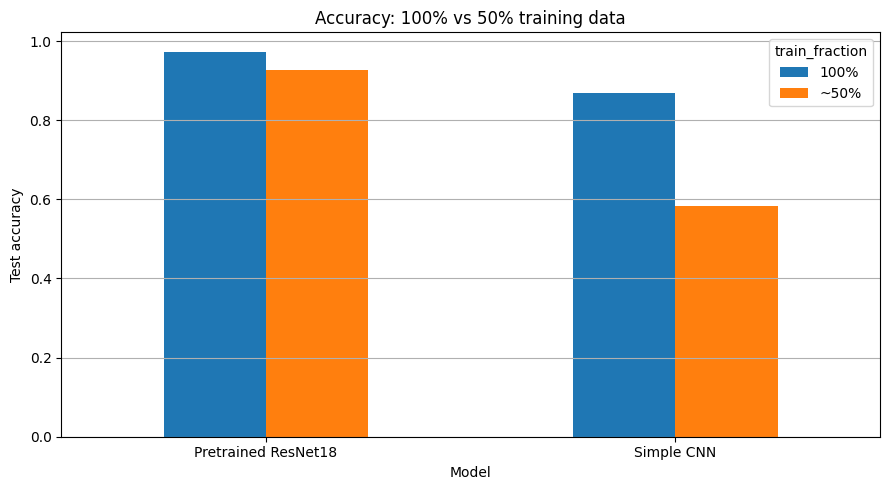

Моделі на 50% даних збережено


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import models

# 1. Порівняння моделей, навчених на 100% даних

print("Порівняння Simple CNN та ResNet18")

full_results = pd.DataFrame([
    {
        "model": "Simple CNN",
        "test_accuracy": cnn_acc,
        "macro_F1": cnn_f1,
        "seconds": cnn_sec
    },
    {
        "model": "ResNet18 pretrained",
        "test_accuracy": resnet_acc,
        "macro_F1": resnet_f1,
        "seconds": resnet_sec
    }
])

display(full_results)

# Графіки валідаційних втрат
plt.figure(figsize=(9, 5))

plt.plot(
    cnn_hist["val"],
    marker="o",
    label="Simple CNN"
)

plt.plot(
    resnet_hist["val"],
    marker="o",
    label="Pretrained ResNet18"
)

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Validation loss comparison")
plt.legend()
plt.grid(True)
plt.show()


# 2. Формуємо 50% навчальних груп без розділення дублікатів

half_g, _ = train_test_split(
    train_g,
    train_size=0.5,
    random_state=SEED,
    stratify=[group_labels[g] for g in train_g]
)

half = expand_groups(half_g)

print("\nРозміри навчальних вибірок:")
print("Повна train:", len(tr))
print("Скорочена train:", len(half))
print("Validation:", len(va))
print("Test:", len(te))

# Перевірка перетинання точних дублікатів
half_hashes = get_hashes(set(half))

assert not (half_hashes & val_h)
assert not (half_hashes & test_h)

print("Перевірка успішна: точні дублікати не перетинаються")


# 3. Навчання нової Simple CNN на 50% даних

print("\nНавчання Simple CNN на 50% груп")

half_cnn = SimpleCNN(num_classes).to(device)

half_dl = DataLoader(
    Subset(img_ds, half),
    batch_size=64,
    shuffle=True,
    num_workers=2
)

half_hist, half_sec = fit_image(
    half_cnn,
    half_dl,
    image_va,
    epochs=5
)

half_acc, half_f1 = image_test(
    half_cnn,
    image_te
)

print("CNN 50% accuracy:", half_acc)
print("CNN 50% Macro F1:", half_f1)


# 4. Навчання нової pretrained ResNet18 на 50% даних

print("\nНавчання ResNet18 на 50% груп")

resnet_half = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

for p in resnet_half.parameters():
    p.requires_grad = False

for p in resnet_half.layer4.parameters():
    p.requires_grad = True

resnet_half.fc = torch.nn.Linear(
    resnet_half.fc.in_features,
    num_classes
)

resnet_half = resnet_half.to(device)

resnet_half_dl = DataLoader(
    Subset(resnet_ds, half),
    batch_size=64,
    shuffle=True,
    num_workers=2
)

resnet_half_hist, resnet_half_sec = fit_image(
    resnet_half,
    resnet_half_dl,
    resnet_va,
    epochs=5
)

resnet_half_acc, resnet_half_f1 = image_test(
    resnet_half,
    resnet_te
)

print("ResNet18 50% accuracy:", resnet_half_acc)
print("ResNet18 50% Macro F1:", resnet_half_f1)


# 5. Підсумкове порівняння чотирьох експериментів

results = pd.DataFrame([
    {
        "model": "Simple CNN",
        "train_fraction": "100%",
        "accuracy": cnn_acc,
        "macro_F1": cnn_f1,
        "seconds": cnn_sec
    },
    {
        "model": "Simple CNN",
        "train_fraction": "~50%",
        "accuracy": half_acc,
        "macro_F1": half_f1,
        "seconds": half_sec
    },
    {
        "model": "Pretrained ResNet18",
        "train_fraction": "100%",
        "accuracy": resnet_acc,
        "macro_F1": resnet_f1,
        "seconds": resnet_sec
    },
    {
        "model": "Pretrained ResNet18",
        "train_fraction": "~50%",
        "accuracy": resnet_half_acc,
        "macro_F1": resnet_half_f1,
        "seconds": resnet_half_sec
    }
])

print("\nПідсумкова таблиця:")
display(results)


# 6. Графік порівняння точності

pivot = results.pivot(
    index="model",
    columns="train_fraction",
    values="accuracy"
)

pivot.plot(kind="bar", figsize=(9, 5))
plt.title("Accuracy: 100% vs 50% training data")
plt.ylabel("Test accuracy")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# 7. Збереження навчених моделей

torch.save(
    {
        "model_state": half_cnn.state_dict(),
        "classes": img_ds.classes,
        "history": half_hist
    },
    MODELS / "malimg_cnn_50pct.pth"
)

torch.save(
    {
        "model_state": resnet_half.state_dict(),
        "classes": img_ds.classes,
        "history": resnet_half_hist
    },
    MODELS / "malimg_resnet_50pct.pth"
)

print("Моделі на 50% даних збережено")


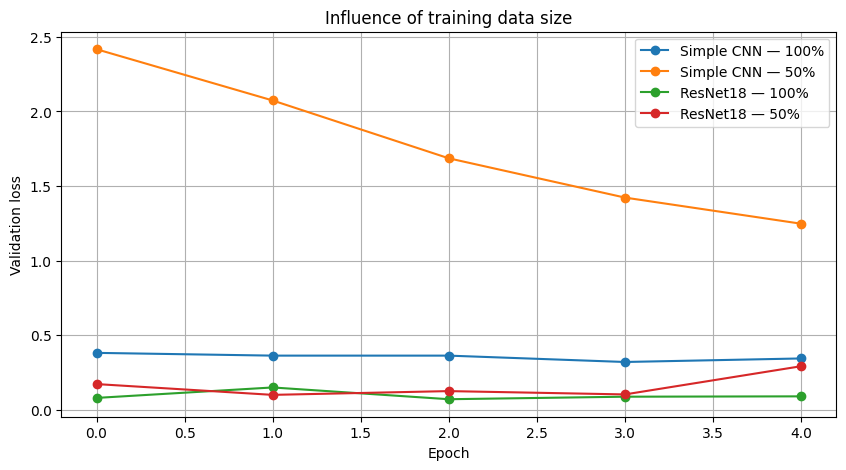

In [52]:
plt.figure(figsize=(10, 5))

plt.plot(
    cnn_hist["val"],
    marker="o",
    label="Simple CNN — 100%"
)

plt.plot(
    half_hist["val"],
    marker="o",
    label="Simple CNN — 50%"
)

plt.plot(
    resnet_hist["val"],
    marker="o",
    label="ResNet18 — 100%"
)

plt.plot(
    resnet_half_hist["val"],
    marker="o",
    label="ResNet18 — 50%"
)

plt.xlabel("Epoch")
plt.ylabel("Validation loss")
plt.title("Influence of training data size")
plt.legend()
plt.grid(True)
plt.show()


На графіку порівняно динаміку валідаційних втрат двох згорткових нейронних мереж за використання повної та скороченої навчальних вибірок. Найбільші значення validation loss спостерігалися для Simple CNN, навченої приблизно на 50% даних. Хоча протягом п'яти епох втрати поступово зменшувалися, вони залишалися значно вищими, ніж в інших експериментах.

Модель ResNet18 продемонструвала нижчі валідаційні втрати за обох обсягів навчальних даних. При використанні скороченої вибірки наприкінці навчання спостерігалося певне зростання validation loss, однак загалом модель зберегла високу якість класифікації.

Отримані результати свідчать, що в межах проведеного експерименту попередньо навчена ResNet18 виявилася менш чутливою до зменшення обсягу навчальних даних, ніж Simple CNN.

***Аналіз впливу навчальної вибірки.*** На повній навчальній вибірці було 6 540 зображень, на скороченій — 3 268. При зменшенні кількості зображень Simple CNN втратила значну частину точності: Accuracy знизилася з 86,96% до 58,24%, а Macro F1 — з 0,8208 до 0,3119. Валідаційні втрати в скороченому експерименті ще зменшувалися до п'ятої епохи, тому модель, можливо, просто не встигла досягти стійкої збіжності за встановлений час.

Для ResNet18 зміна була помітно меншою: Accuracy знизилася з 97,35% до 92,77%, Macro F1 — з 0,9193 до 0,8972. При цьому pretrained модель уже на початку навчання демонструвала високу валідаційну точність. Отже, використання попередньо навчених ваг дало перевагу за обмеженої кількості навчальних зразків.

***Висновки до завдання 2.*** У проведеному експерименті ResNet18 показала вищу якість класифікації, швидше досягала високої валідаційної точності й менше втрачала її після скорочення навчальної вибірки. Simple CNN була простішою та швидшою за тривалістю одного навчального запуску, однак її результати виявилися чутливішими до кількості даних. Для коректності оцінювання попередньо було усунуто перетинання точних файлових дублікатів. Разом із тим можливість майже однакових зображень та відсутність повторних запусків на інших поділах залишаються обмеженнями дослідження.
# **3. Класифікація текстів за допомогою GRU**
## **3.1. Завантаження та очищення текстових даних**
У третьому завданні використано Scam and Non-Scam Call Conversation Dataset із лабораторної №2. Два текстові файли містили по 400 записів: у English_NonScam.txt наведено звичайні розмови (клас 0), а у English_Scam.txt — шахрайські (клас 1). Один непорожній рядок файлу розглядався як окремий текстовий запис.

Перед побудовою моделей тексти приведено до нижнього регістру, прибрано позначки у квадратних дужках, числа, знаки пунктуації та зайві пробіли. Після очищення видалено дублікати й перевірено, чи немає однакових текстів із суперечливими мітками класів.

In [51]:
from pathlib import Path
paths={0:DATA/'English_NonScam.txt',1:DATA/'English_Scam.txt'}
assert all(p.is_file() for p in paths.values()),f'Потрібні TXT у {DATA}'
rows=[]
for label,path in paths.items():
    raw=path.read_text(encoding='utf-8-sig')
    lines=[s.strip() for s in raw.splitlines() if s.strip()]
    print(path.name, 'непорожніх рядків:', f'{len(lines)},', 'наприклад:', repr(lines[0][:100]) if lines else '')
    assert len(lines)==400, f'{path.name}: очікуємо 400 рядків, перевірте файл'
    rows.extend({'text':s,'label':label} for s in lines)
calls=pd.DataFrame(rows)
def clean_text(s):
    s=re.sub(r'\[[^\]]*\]',' ',s.lower())
    s=re.sub(r'[^a-z\s]',' ',s)
    return ' '.join(s.split())
calls['clean']=calls['text'].map(clean_text)
calls=calls[calls.clean.str.len()>0].copy()
conflicts=calls.groupby('clean').label.nunique()
calls=calls[~calls.clean.isin(conflicts[conflicts>1].index)]
calls=calls.drop_duplicates('clean').reset_index(drop=True)
texts=calls['clean'].tolist();targets=calls['label'].tolist()
print('Після очищення:',len(calls))
print('Розподіл:',calls.label.value_counts().to_dict())
assert len(set(targets))==2
print('Приклад очищеного тексту:',texts[0][:200])

English_NonScam.txt непорожніх рядків: 400, наприклад: '[Greetings], this is [Company] Utilities. We are upgrading our systems and offering a complimentary '
English_Scam.txt непорожніх рядків: 400, наприклад: '1.\t[Greetings] I am calling from the government grants department. You have been selected to receive'
Після очищення: 793
Розподіл: {0: 400, 1: 393}
Приклад очищеного тексту: this is utilities we are upgrading our systems and offering a complimentary smart meter installation to improve service efficiency can we schedule a visit to your home this week the appointment takes 


***Результат очищення.*** Початково було 800 записів, порівну між класами. Після обробки залишилося 793 унікальні тексти: 400 звичайних та 393 шахрайські розмови. Отриманий обсяг відповідає підготовленому датасету з попередньої лабораторної роботи й використовується в наступних експериментах.
## **3.2. Токенізація, словник і приведення текстів до однакової довжини**
Щоб рекурентна нейронна мережа могла працювати з текстами, виконано токенізацію та замінено слова числовими індексами. Спочатку поділено записи на Train, Validation та Test зі збереженням співвідношення класів, а словник побудовано лише за навчальною частиною. Це важливо, оскільки використання тестових текстів для формування словника створювало б небажаний витік інформації.

Для невідомих слів передбачено токен UNK, а для доповнення коротких послідовностей — PAD. Довжину текстів обмежено 256&nbsp;токенами; коротші послідовності доповнювалися нулями, а довші мали б обрізатися. Також сформовано PyTorch DataLoader для кожної вибірки.

In [ ]:
def tokenize(s): return re.findall(r"[a-z]+(?:'[a-z]+)?",s.lower())
idx=np.arange(len(targets));y=np.array(targets)
trv,te_txt=train_test_split(idx,test_size=.2,stratify=y,random_state=SEED)
tr_txt,va_txt=train_test_split(trv,test_size=.2,stratify=y[trv],random_state=SEED)
counts=collections.Counter(w for i in tr_txt for w in tokenize(texts[i]))
vocab={'<PAD>':0,'<UNK>':1}
for word,n in counts.most_common(20000):
    if n>=2:vocab[word]=len(vocab)
MAX_LEN=256
lengths=np.array([min(MAX_LEN,max(1,len(tokenize(t)))) for t in texts],dtype=np.int64)
def encode(text):
    toks=tokenize(text)[:MAX_LEN]
    indices=[vocab.get(w,1) for w in toks]
    return indices+[0]*(MAX_LEN-len(indices))
X_txt=np.array([encode(t) for t in texts],dtype=np.int64)
def txtloader(ids,shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(X_txt[ids]),torch.tensor(lengths[ids],dtype=torch.long),torch.tensor(y[ids],dtype=torch.float32)),batch_size=32,shuffle=shuffle)
txt_tr=txtloader(tr_txt,True);txt_va=txtloader(va_txt);txt_te=txtloader(te_txt)
truncated=sum(len(tokenize(t))>MAX_LEN for t in texts)
print('Vocabulary:',len(vocab))
print(f'Train / Val / Test: {len(tr_txt)} / {len(va_txt)} / {len(te_txt)}')
print('Tensor:',X_txt.shape)
print('Обрізано розмов:',truncated,'із',len(texts))

Vocabulary: 1526
Train / Val / Test: 507 / 127 / 159
Tensor: (793, 256)
Обрізано розмов: 0 із 793


***Результат підготовки текстів.*** Словник містить 1 526 елементів, у тому числі спеціальні індекси. Сформовано 507 навчальних, 127&nbsp;валідаційних і 159 тестових записів. Підготовлена матриця має розмірність (793, 256). Перевірка показала, що жоден текст не перевищував обраної максимальної довжини, тому втрати інформації через обрізання не було. Отже, обраний спосіб передобробки підходить для цього набору текстів.
## **3.3. Навчання GRU з випадковими Embedding**
Для першого експерименту створено рекурентну нейронну мережу GRU, яка отримує на вході послідовність індексів слів. Шар Embedding перетворює їх на 50-вимірні вектори; на початку ці вектори мають випадкові значення й поступово коригуються під час навчання. GRU має 64 приховані нейрони, а вихідний лінійний шар формує оцінку належності тексту до класу Scam.

Для роботи з різною фактичною довжиною текстів застосовано pack_padded_sequence. Модель навчалася п'ять епох із оптимізатором Adam та функцією втрат BCEWithLogitsLoss. Після цього оцінено її на тестовій вибірці та побудовано криві навчальних і валідаційних втрат.

Epoch 1: train=0.6849, val=0.6557
Epoch 2: train=0.6257, val=0.5993
Epoch 3: train=0.5391, val=0.4612
Epoch 4: train=0.3845, val=0.3543
Epoch 5: train=0.2617, val=0.2960
Random embedding accuracy/F1/time: 0.8679245283018868 0.8551724137931035 7.837494352999784

              precision    recall  f1-score   support

           0       0.82      0.95      0.88        80
           1       0.94      0.78      0.86        79

    accuracy                           0.87       159
   macro avg       0.88      0.87      0.87       159
weighted avg       0.88      0.87      0.87       159



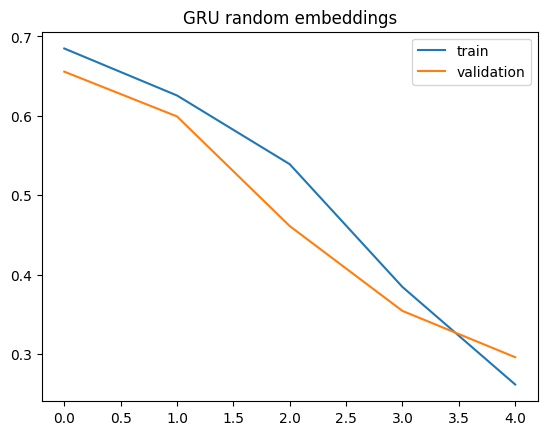

In [ ]:
class TextGRU(nn.Module):
    def __init__(self,vocab_size,embed_size=50,hidden=64,pretrained=None):
        super().__init__()
        self.embedding=nn.Embedding(vocab_size,embed_size,padding_idx=0)
        if pretrained is not None:
            self.embedding.weight.data.copy_(torch.tensor(pretrained,dtype=torch.float32))
        self.gru=nn.GRU(embed_size,hidden,batch_first=True)
        self.fc=nn.Linear(hidden,1)
    def forward(self,x,lengths):
        emb=self.embedding(x)
        packed=pack_padded_sequence(emb,lengths.cpu(),batch_first=True,enforce_sorted=False)
        _,h=self.gru(packed)
        return self.fc(h[-1]).squeeze(1)
text_loss=nn.BCEWithLogitsLoss()
def fit_text(model,epochs=5):
    model=model.to(device);opt=torch.optim.Adam(model.parameters(),lr=.001)
    history={'train':[],'val':[]};start=time.perf_counter()
    for ep in range(epochs):
        for loader,training,key in [(txt_tr,True,'train'),(txt_va,False,'val')]:
            model.train(training);total=loss_sum=0
            for xb,lens,yb in loader:
                xb,yb=xb.to(device),yb.to(device)
                if training:opt.zero_grad()
                with torch.set_grad_enabled(training):
                    logits=model(xb,lens);loss=text_loss(logits,yb)
                    if training:loss.backward();opt.step()
                total+=len(yb);loss_sum+=loss.item()*len(yb)
            history[key].append(loss_sum/total)
        print(f'Epoch {ep+1}: train={history["train"][-1]:.4f}, val={history["val"][-1]:.4f}')
    return history,time.perf_counter()-start
def eval_text(model):
    model.eval();ys=[];ps=[]
    with torch.no_grad():
        for xb,lens,yb in txt_te:
            pred=(torch.sigmoid(model(xb.to(device),lens)).cpu().numpy()>=.5).astype(int)
            ps.extend(pred);ys.extend(yb.numpy().astype(int))
    return accuracy_score(ys,ps),f1_score(ys,ps),classification_report(ys,ps,zero_division=0)
random_gru=TextGRU(len(vocab))
random_hist,random_sec=fit_text(random_gru,epochs=5)
random_acc,random_f1,random_report=eval_text(random_gru)
print('Random embedding accuracy/F1/time:',random_acc,random_f1,random_sec)
print()
print(random_report)
plt.plot(random_hist['train'],label='train');plt.plot(random_hist['val'],label='validation');plt.legend();plt.title('GRU random embeddings');plt.show()
torch.save({'model_state':random_gru.state_dict(),'vocab':vocab,'history':random_hist},MODELS/'scam_gru_random.pth')

***Аналіз GRU з випадковими Embedding.*** На тестовій вибірці модель показала 86,79% Accuracy, а F1-score для класу 1 (Scam) становив 0,8552. Навчання тривало приблизно 7,84 с. Протягом п'яти епох train loss зменшився з 0,6849 до 0,2617, validation loss — з 0,6557 до 0,2960. Обидві криві спадали, тому на цьому відрізку виражених ознак перенавчання немає.

Водночас classification_report показав, що recall для шахрайських розмов становив 0,78. Тобто частину справді шахрайських текстів модель помилково визначила як звичайні. Для задачі виявлення шахрайства це суттєве обмеження, навіть якщо загальна Accuracy виглядає достатньо високою.
## **3.4. Навчання GRU з попередньо навченими GloVe**
Другу модель побудовано за тією самою архітектурою GRU, але замість випадкових векторів використано готові 50-вимірні представлення слів glove-wiki-gigaword-50. Завдяки попередньому навчанню GloVe слова отримують початкові вектори, сформовані на великому текстовому корпусі. Якщо для певного слова готового вектора не було, залишалося випадкове початкове значення; для PAD використовувався нульовий вектор.

Для чистого порівняння збережено ті самі вибірки, кількість епох та процедуру навчання. Ваги Embedding дозволено оновлювати під час оптимізації.

Завантаження pretrained GloVe...
[==================================================] 100.0% 66.0/66.0MB downloaded
Збіги зі словником GloVe: 1520 з 1526
Epoch 1: train=0.6687, val=0.6383
Epoch 2: train=0.6024, val=0.5156
Epoch 3: train=0.4267, val=0.2745
Epoch 4: train=0.2820, val=0.1870
Epoch 5: train=0.2033, val=0.1999
GloVe accuracy/F1/time: 0.9308176100628931 0.9341317365269461 7.723873549999553
              precision    recall  f1-score   support

           0       0.99      0.88      0.93        80
           1       0.89      0.99      0.93        79

    accuracy                           0.93       159
   macro avg       0.94      0.93      0.93       159
weighted avg       0.94      0.93      0.93       159



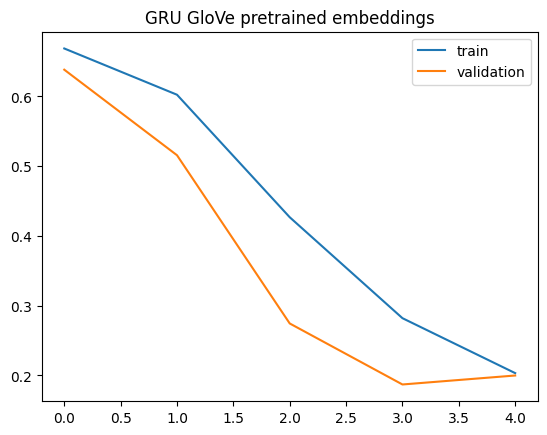

GloVe GRU checkpoint збережено


In [ ]:
import gensim.downloader as api
print('Завантаження pretrained GloVe...')
glove=api.load('glove-wiki-gigaword-50')
emb=np.random.normal(scale=.05,size=(len(vocab),50)).astype('float32')
emb[0]=0
matched=0
for word,ix in vocab.items():
    if word in glove:
        emb[ix]=glove[word];matched+=1
print('Збіги зі словником GloVe:',matched,'з',len(vocab))
glove_gru=TextGRU(len(vocab),pretrained=emb)
glove_hist,glove_sec=fit_text(glove_gru,epochs=5)
glove_acc,glove_f1,glove_report=eval_text(glove_gru)
print('GloVe accuracy/F1/time:',glove_acc,glove_f1,glove_sec)
print(glove_report)
plt.plot(glove_hist['train'],label='train');plt.plot(glove_hist['val'],label='validation');plt.legend();plt.title('GRU GloVe pretrained embeddings');plt.show()
torch.save({'model_state':glove_gru.state_dict(),'vocab':vocab,'history':glove_hist},MODELS/'scam_gru_glove.pth')
print('GloVe GRU checkpoint збережено')

***Аналіз GRU з GloVe.*** Програма повідомила про 1 520 збігів із 1 526 елементів словника. Це означає, що майже для всіх слів, представлених у навчальному словнику, знайдено готові вектори; однак при точному підрахунку покриття потрібно окремо враховувати службові токени.

Після п'яти епох модель досягла 93,08% Accuracy та 0,9341 F1-score для класу Scam, витративши приблизно 7,72 с. Найнижчі валідаційні втрати (0,1870) отримано на четвертій епосі, а на п'ятій вони трохи зросли до 0,1999. Це може свідчити про коливання навчання, але саме по собі не доводить перенавчання.

За тестовим звітом recall для класу Scam становив 0,99, а для NonScam — 0,88. Отже, модель виявляла більшість шахрайських текстів, проте частину звичайних розмов помилково позначала як шахрайські.
## **3.5. Порівняння двох підходів до Embedding**
На завершення порівняли обидві GRU за F1-score, тестовою точністю, часом навчання та швидкістю зменшення валідаційних втрат. У цьому завданні функція eval_text() обчислює f1_score(ys, ps) без average='macro', тому наведений у таблиці показник test_F1 є F1‑score для позитивного класу 1 (Scam). Він не тотожний Macro F1 із попередніх завдань.

,model,test_accuracy,test_F1,training_seconds
0,GRU + random Embedding,0.867925,0.855172,7.837494
1,GRU + pretrained GloVe,0.930818,0.934132,7.723874


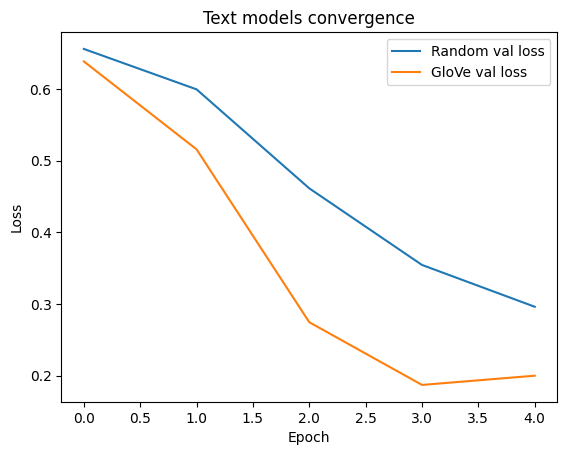

In [ ]:
display(pd.DataFrame([
  {'model':'GRU + random Embedding','test_accuracy':random_acc,'test_F1':random_f1,'training_seconds':random_sec},
  {'model':'GRU + pretrained GloVe','test_accuracy':glove_acc,'test_F1':glove_f1,'training_seconds':glove_sec}
]))
plt.plot(random_hist['val'],label='Random val loss');plt.plot(glove_hist['val'],label='GloVe val loss');plt.xlabel('Epoch');plt.ylabel('Loss');plt.legend();plt.title('Text models convergence');plt.show()

***Висновки до завдання 3.*** Використання попередньо навчених GloVe у проведеному експерименті покращило точність із 86,79% до 93,08%, тобто на 6,29 відсоткового пункта. F1-score для класу Scam зріс із 0,8552 до 0,9341, тоді як час навчання залишився майже однаковим: 7,84 с і 7,72 с. За графіками модель із GloVe також швидше досягала нижчого validation loss.

Отже, для цього текстового датасету використання pretrained embeddings дало кращу якість, ніж випадкова ініціалізація. Водночас оцінювання проводилося на одному поділі даних, а результат може залежати від початкових ваг та складу навчальної вибірки. Тому висновки стосуються саме проведених експериментів, а не всіх можливих моделей GRU.
# **Загальні висновки**
У ході виконання лабораторної роботи було досліджено три підходи до нейромережевої класифікації — MLP для табличних даних, CNN для зображень і GRU для текстів. Усі експерименти виконано за допомогою PyTorch із попередньою підготовкою даних та окремим оцінюванням моделей на тестових вибірках.

На мережевому датасеті TON-IoT повнозв'язана нейронна мережа показала високу точність, але Random Forest виявився точнішим і швидшим. У задачі класифікації Malimg найкращий результат продемонструвала ResNet18, попередньо навчена на ImageNet. Вона також значно краще зберегла точність після зменшення кількості навчальних зображень, хоча потребувала більше часу. Для телефонних розмов модель GRU з GloVe перевершила GRU із випадково ініціалізованими Embedding за точністю та F1-score позитивного класу.

Під час виконання роботи встановлено, що якість моделі залежить не тільки від архітектури, а й від способу передобробки даних. Особливо важливим етапом стала перевірка дублікатів у Malimg: початковий розподіл містив однакові файли в різних вибірках, тому його довелося виправити до навчання моделей. Також графіки навчання допомогли оцінити характер збіжності й помітити можливі коливання валідаційних показників.

Таким чином, поставлену мету лабораторної роботи досягнуто: було побудовано та порівняно нейронні мережі для трьох типів даних і проаналізовано їхні переваги та обмеження. Отримані висновки стосуються конкретних наборів даних, налаштувань і запусків моделей.
# **Обмеження дослідження**
Під час інтерпретації результатів враховано, що контроль SHA-256 виявляє лише точні дублікати Malimg, але не майже однакові зображення. Експерименти проводилися на одному поділі даних, тому для більш надійних узагальнень доцільно повторити навчання з іншими початковими значеннями генератора випадкових чисел. Час навчання залежить від обчислювального середовища; у цьому запуску використано CPU. Окрім того, короткочасне зростання validation loss саме по собі не є достатнім доказом перенавчання.